# Level 2 – Task 2: Wine Quality Prediction

**Internship:** Oasis Infobyte – Data Analytics  
**Objective:** Compare three classifiers for wine quality categories.

## Workflow
1. Download and inspect UCI red wine quality data.
2. Explore class balance and feature distributions.
3. Create low/medium/high quality classes and justify grouping.
4. Split with stratification.
5. Train Random Forest, SGD and SVC.
6. Evaluate accuracy, classification report and confusion matrices.
7. Show Random Forest feature importance and compare models.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

sns.set_theme(style="whitegrid")


## 1. Load dataset

The data is the UCI Red Wine Quality dataset. It contains physicochemical measurements and a quality score. The notebook downloads it when run in Colab.

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-red.csv"
wine = pd.read_csv(url, sep=";")
display(wine.head())
print("Shape:", wine.shape)
display(wine.info())
display(wine.describe().T)
print("Missing values:")
display(wine.isna().sum())


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Shape: (1599, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


None

,count,mean,std,min,25%,50%,75%,max
fixed acidity,1599.0,8.319637,1.741096,4.60000,7.1000,7.90000,9.200000,15.90000
volatile acidity,1599.0,0.527821,0.179060,0.12000,0.3900,0.52000,0.640000,1.58000
citric acid,1599.0,0.270976,0.194801,0.00000,0.0900,0.26000,0.420000,1.00000
residual sugar,1599.0,2.538806,1.409928,0.90000,1.9000,2.20000,2.600000,15.50000
chlorides,1599.0,0.087467,0.047065,0.01200,0.0700,0.07900,0.090000,0.61100
free sulfur dioxide,1599.0,15.874922,10.460157,1.00000,7.0000,14.00000,21.000000,72.00000
total sulfur dioxide,1599.0,46.467792,32.895324,6.00000,22.0000,38.00000,62.000000,289.00000
density,1599.0,0.996747,0.001887,0.99007,0.9956,0.99675,0.997835,1.00369
pH,1599.0,3.311113,0.154386,2.74000,3.2100,3.31000,3.400000,4.01000
sulphates,1599.0,0.658149,0.169507,0.33000,0.5500,0.62000,0.730000,2.00000


Missing values:


,0
fixed acidity,0
volatile acidity,0
citric acid,0
residual sugar,0
chlorides,0
free sulfur dioxide,0
total sulfur dioxide,0
density,0
pH,0
sulphates,0


## 2. Class distribution and EDA

The original score is ordinal and some scores occur much less often than others. This imbalance can make accuracy alone misleading, so we also inspect precision, recall and F1-score.

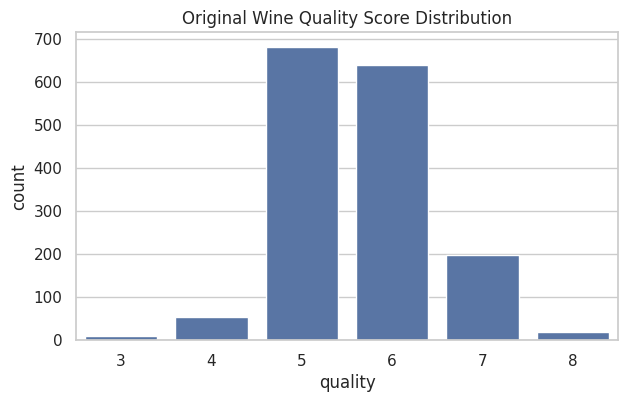

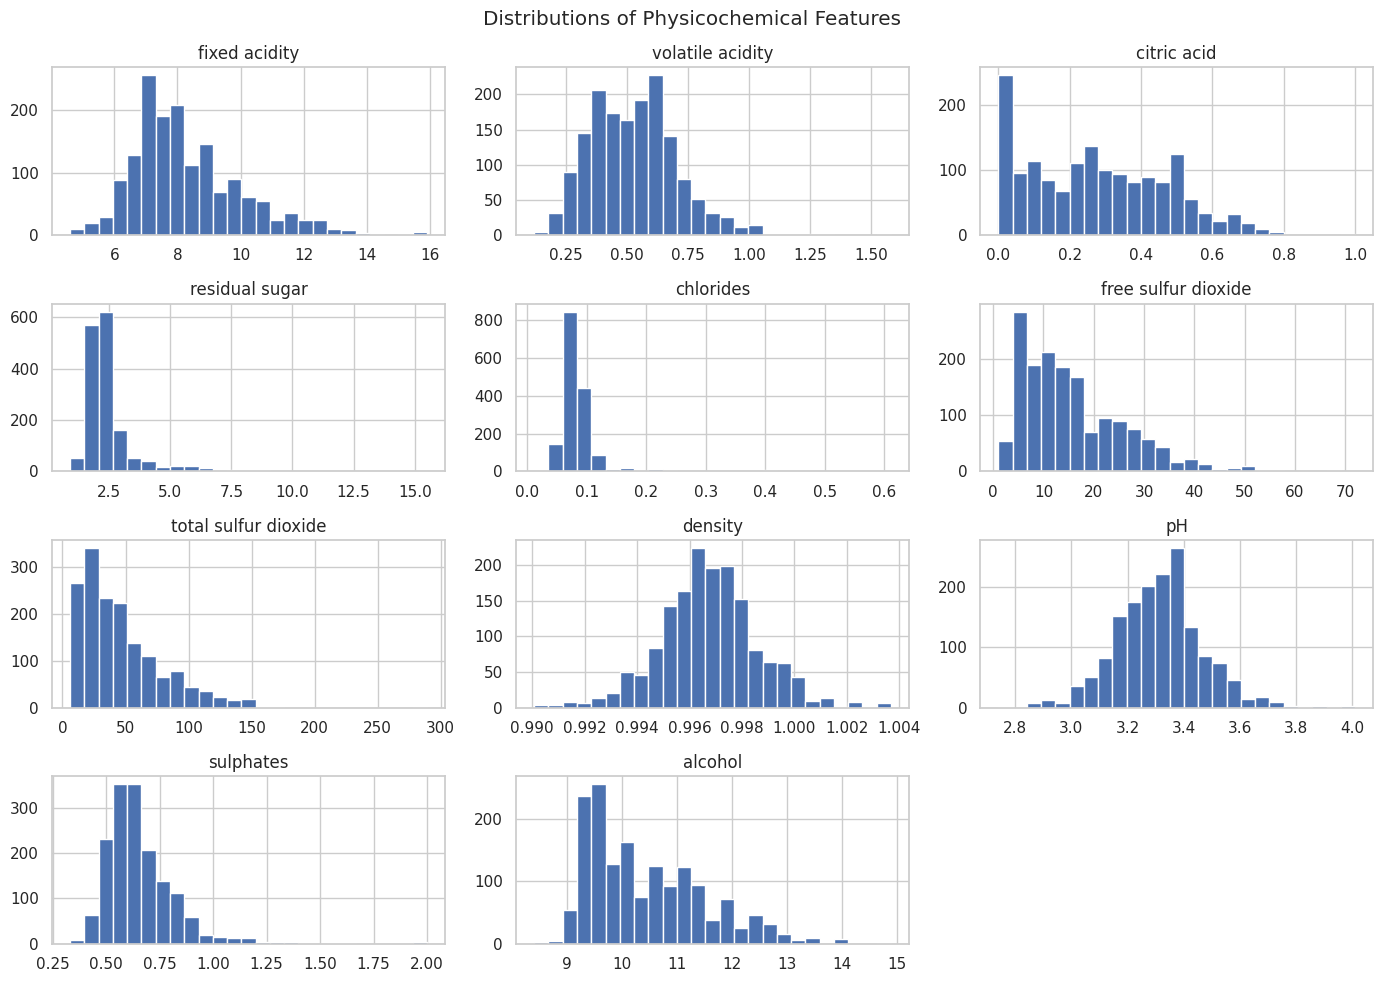

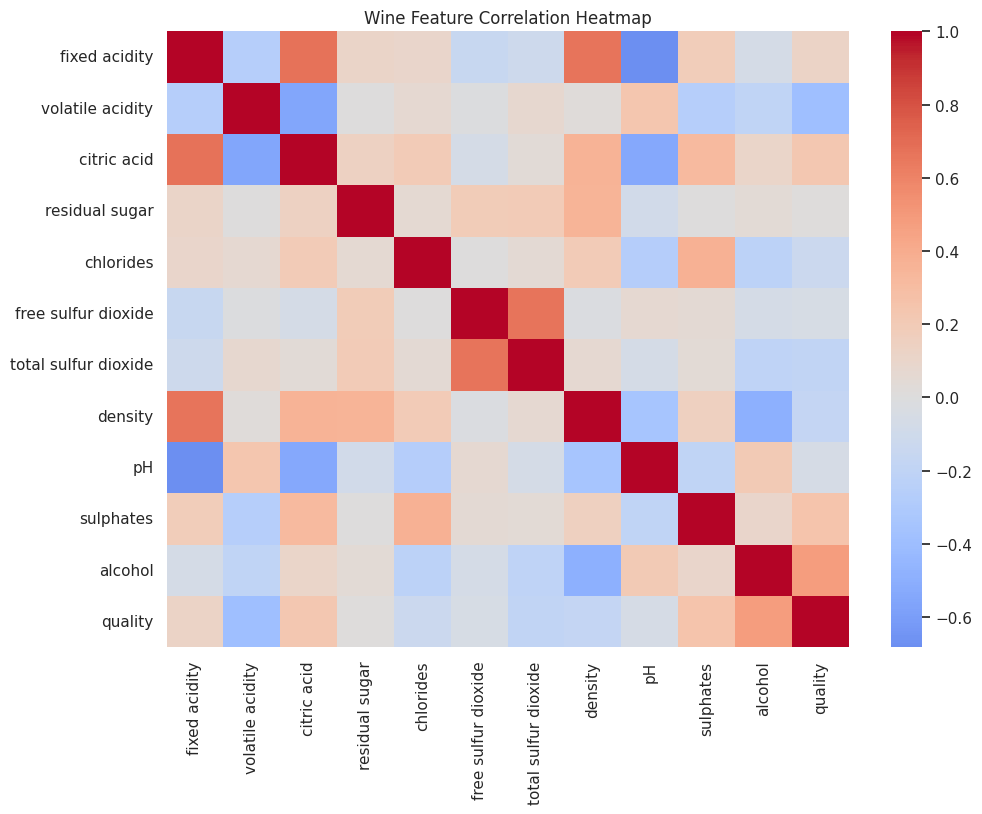

In [3]:
plt.figure(figsize=(7,4))
sns.countplot(data=wine, x="quality")
plt.title("Original Wine Quality Score Distribution")
plt.show()

wine.drop(columns="quality").hist(figsize=(14,10), bins=25)
plt.suptitle("Distributions of Physicochemical Features")
plt.tight_layout()
plt.show()

plt.figure(figsize=(11,8))
sns.heatmap(wine.corr(numeric_only=True), cmap="coolwarm", center=0)
plt.title("Wine Feature Correlation Heatmap")
plt.show()


## 3. Feature engineering: Low / Medium / High

For a three-class task, scores are grouped as:
- Low: quality ≤ 5
- Medium: quality = 6
- High: quality ≥ 7

This reduces the number of rare individual score classes and creates an interpretable target. The grouping is a modelling choice, not a universal wine-rating standard.

,count
quality_group,
Low,744
Medium,638
High,217


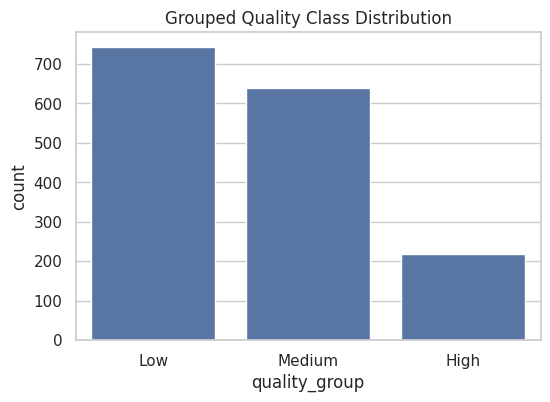

In [4]:
def quality_group(q):
    if q <= 5:
        return "Low"
    elif q == 6:
        return "Medium"
    return "High"

wine["quality_group"] = wine["quality"].apply(quality_group)
display(wine["quality_group"].value_counts())
plt.figure(figsize=(6,4))
sns.countplot(data=wine, x="quality_group", order=["Low","Medium","High"])
plt.title("Grouped Quality Class Distribution")
plt.show()


## 4. Prepare features and stratified split

The original numeric quality score is removed from predictors because it directly defines the target group. Stratification preserves class proportions across train and test sets.

In [5]:
X = wine.drop(columns=["quality", "quality_group"])
y = wine["quality_group"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Train distribution:")
display(y_train.value_counts(normalize=True).rename("proportion"))
print("Test distribution:")
display(y_test.value_counts(normalize=True).rename("proportion"))


Train distribution:


,proportion
quality_group,
Low,0.465207
Medium,0.398749
High,0.136044


Test distribution:


,proportion
quality_group,
Low,0.465625
Medium,0.400000
High,0.134375


## 5. Train three classifiers

Random Forest is tree-based and does not require feature scaling. SGD and SVC are trained with standardized features.

In [6]:
models = {
    "Random Forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("model", RandomForestClassifier(n_estimators=300, random_state=42,
                                         class_weight="balanced"))
    ]),
    "SGD Classifier": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SGDClassifier(random_state=42, max_iter=2000,
                                class_weight="balanced"))
    ]),
    "SVC": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", SVC(class_weight="balanced"))
    ])
}

predictions = {}
rows = []
for name, model in models.items():
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)
    predictions[name] = y_pred
    rows.append({"Model": name, "Accuracy": accuracy_score(y_test, y_pred)})
    print("\\n", "="*60, "\\n", name)
    print(classification_report(y_test, y_pred, zero_division=0))
display(pd.DataFrame(rows).sort_values("Accuracy", ascending=False))


\n ============================================================ \n Random Forest
              precision    recall  f1-score   support

        High       0.69      0.56      0.62        43
         Low       0.81      0.83      0.82       149
      Medium       0.70      0.72      0.71       128

    accuracy                           0.75       320
   macro avg       0.73      0.70      0.71       320
weighted avg       0.75      0.75      0.75       320

\n ============================================================ \n SGD Classifier
              precision    recall  f1-score   support

        High       0.23      0.33      0.27        43
         Low       0.70      0.74      0.72       149
      Medium       0.51      0.41      0.45       128

    accuracy                           0.55       320
   macro avg       0.48      0.49      0.48       320
weighted avg       0.56      0.55      0.55       320

\n ============================================================ \n SVC
    

,Model,Accuracy
0,Random Forest,0.750000
2,SVC,0.609375
1,SGD Classifier,0.553125


## 6. Confusion matrices

Confusion matrices show which quality groups are most often confused. This is useful when the classes are imbalanced.

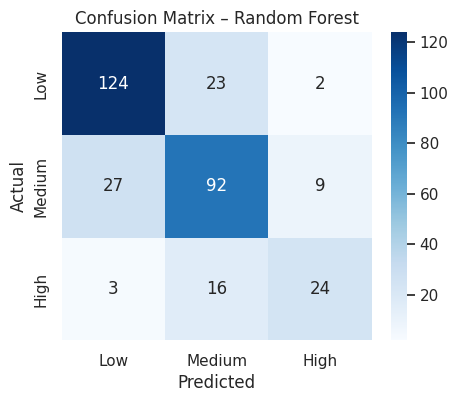

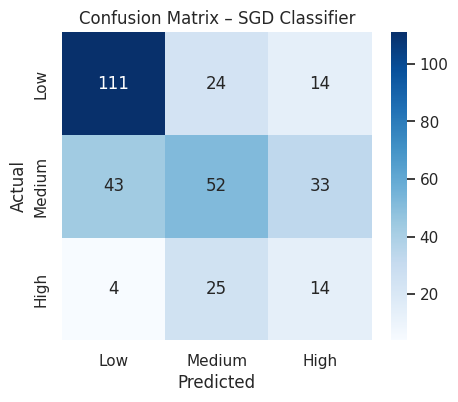

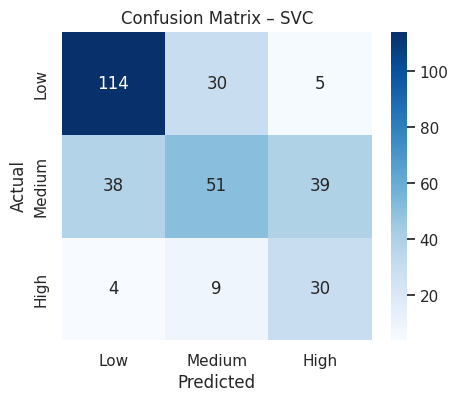

In [7]:
labels = ["Low", "Medium", "High"]
for name, y_pred in predictions.items():
    cm = confusion_matrix(y_test, y_pred, labels=labels)
    plt.figure(figsize=(5,4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=labels, yticklabels=labels)
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"Confusion Matrix – {name}")
    plt.show()


## 7. Random Forest feature importance

,Feature,Importance
10,alcohol,0.166144
9,sulphates,0.116120
1,volatile acidity,0.110924
6,total sulfur dioxide,0.094993
2,citric acid,0.088965
7,density,0.082866
4,chlorides,0.076503
0,fixed acidity,0.070566
8,pH,0.067648
3,residual sugar,0.062798


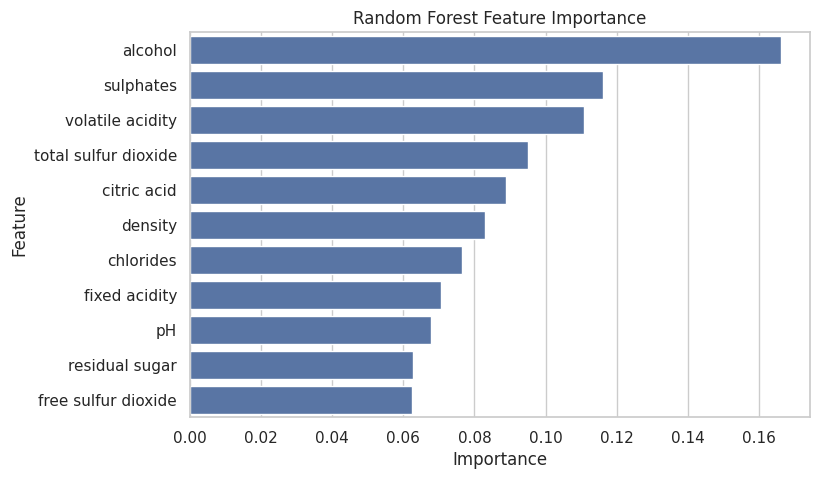

In [8]:
rf = models["Random Forest"].named_steps["model"]
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf.feature_importances_
}).sort_values("Importance", ascending=False)
display(importance)

plt.figure(figsize=(8,5))
sns.barplot(data=importance, x="Importance", y="Feature")
plt.title("Random Forest Feature Importance")
plt.show()


## 8. Model comparison and conclusion

Use the accuracy table together with each classification report and confusion matrix. Select the model based on balanced performance across classes, not accuracy alone. Note limitations: the dataset is relatively small, quality labels are subjective, and grouped classes simplify the original rating scale.